# 1. P-FFA search over frequency

The simplest loki search: a pulsar with no orbital motion, searched over
spin frequency with the P-FFA, loki's variant of the Fast Folding
Algorithm. The P-FFA folds the
time series at every trial frequency in the band and scores each folded
profile with boxcar matched filters.

loki shifts and adds profiles in one of two ways:

- **time domain** (`use_fourier=False`): shifts are rounded to whole
  phase bins;
- **Fourier domain** (`use_fourier=True`): shifts are applied as phase
  ramps on the Fourier transform of each profile, so fractional-bin
  shifts are exact.

This notebook runs both on the same data and compares the recovered
signal. Runtime: about 10 seconds; memory: about 3 GB.

In [1]:
%matplotlib inline
from matplotlib import pyplot as plt

from loki import libloki
from loki.libloki.configs import PulsarSearchConfig
from loki.search import ffa_search
from pyloki.simulation.pulse import PulseSignalConfig

libloki.set_log_level("warning")  # hide loki's per-step info messages
SEED = 1
NTHREADS = 4  # CPU threads; raise it on a machine of your own

## Simulated data

A 7 ms pulsar with a Gaussian pulse of 5 % duty cycle, injected into white
noise at a folded S/N of 10. The observation is 2^24 samples of 64 µs
(about 18 minutes). The plot shows the time series folded at the true
period: the pulse is a straight vertical track because the period is
constant.

T_obs = 1073.7 s, true frequency = 142.857143 Hz


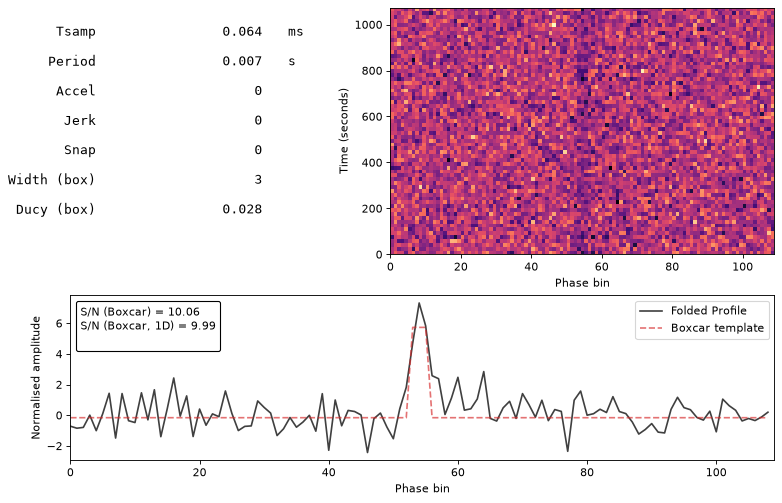

In [2]:
cfg = PulseSignalConfig(
    period=0.007,
    dt=64e-6,
    nsamps=2**24,
    snr=10,
    ducy=0.05,
    seed=SEED,
)
tim_data = cfg.generate(shape="gaussian")
print(f"T_obs = {cfg.tobs:.1f} s, true frequency = {cfg.freq:.6f} Hz")
tim_data.plot_fold(cfg.freq, cfg.fold_bins, dpi=80)
plt.show()

## Search configuration

| parameter | value | meaning |
|---|---|---|
| `param_limits` | 133.3–153.8 Hz | frequency band (periods 6.5–7.5 ms) |
| `nbins` | 64 | phase bins of the folded profile |
| `eta` | 1 | grid step, as the largest phase drift (in bins) between neighbouring trials |
| `bseg_brute` | 128 samples | segment length folded directly before the P-FFA iterations start |
| `ducy_max`, `wtsp` | 0.5, 1.5 | boxcar widths from one bin up to half the profile, spaced by a factor 1.5 |

In [3]:
def search_config(use_fourier: bool) -> PulsarSearchConfig:
    return PulsarSearchConfig(
        nsamps=cfg.nsamps,
        tsamp=cfg.dt,
        nbins=64,
        eta=1,
        param_limits=[(1 / 0.0075, 1 / 0.0065)],
        bseg_brute=128,
        ducy_max=0.5,
        wtsp=1.5,
        nthreads=NTHREADS,
        use_fourier=use_fourier,
    )


true_values = {"freq": cfg.freq}
results = {}
for use_fourier in (False, True):
    mode = "Fourier" if use_fourier else "time"
    plan, pgram = ffa_search(tim_data, search_config(use_fourier))
    results[mode] = pgram
    print(f"--- {mode} domain: {pgram.snrs.size:,} trials (frequency x width)")
    print(pgram.get_indices_summary(true_values=true_values))
    print(pgram.get_summary())

--- time domain: 14,096,310 trials (frequency x width)


True param indices: (654471,)
Best param indices: (np.int64(654470), np.int64(2))
Best S/N: 8.67
Best Period: 0.007000000738509405
Best freq: 142.85712778552394
Best width: 3


--- Fourier domain: 14,096,310 trials (frequency x width)
True param indices: (654471,)
Best param indices: (np.int64(654470), np.int64(2))
Best S/N: 9.92
Best Period: 0.007000000738509405
Best freq: 142.85712778552394
Best width: 3


## Periodogram

Best S/N over boxcar widths at every trial frequency, for each mode. The
injected pulsar is the single peak at 142.857 Hz; everything else is
noise.

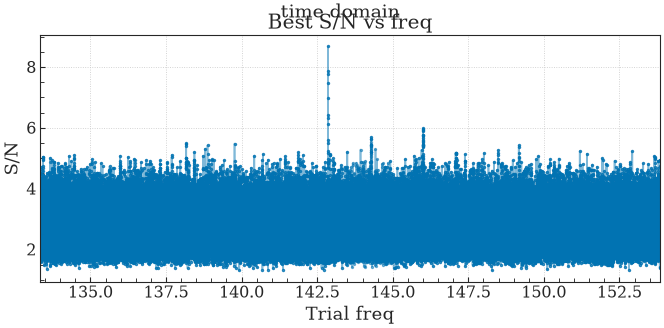

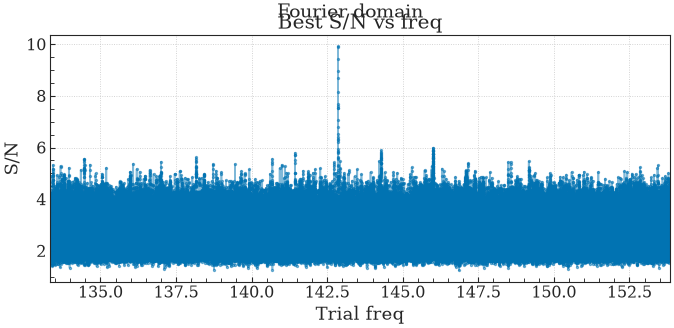

In [4]:
for mode, pgram in results.items():
    fig = pgram.plot_1d("freq", figsize=(10, 4), dpi=80)
    fig.suptitle(f"{mode} domain")
    plt.show()

## Time vs Fourier domain

Both modes find the pulsar at the right frequency. The recovered S/N is
below the injected 10 because the trial grid, the 64-bin profile and
the boxcar widths never match the pulse exactly; exact fractional-bin
shifts remove part of that loss in the Fourier mode.

In [5]:
print(f"{'mode':>8}  {'best S/N':>8}  {'freq error (Hz)':>15}")
for mode, pgram in results.items():
    best = pgram.find_best_params()
    print(f"{mode:>8}  {best['snr']:8.2f}  {best['freq'] - cfg.freq:15.2e}")

    mode  best S/N  freq error (Hz)
    time      8.67        -1.51e-05
 Fourier      9.92        -1.51e-05
